# Directional wavelet analysis of PIV divergence — Part 2: phase evolution, advection and wave propagation

Part 1 built a complex directional wavelet transform W(scale, angle, lat, lon) of a single divergence field
and showed that it recovers localized wave packets. This notebook follows those coefficients **in time**.

## The idea in one paragraph

A wavelet coefficient behaves locally like a plane wave, W ≈ A·exp(i(k·x − ωt)). Between two times Δt apart,
its phase changes by Δφ = −ωΔt. Dividing by the wavenumber gives an apparent **phase speed** along the wavelet
direction θ:

$$c_{obs}(\theta, \lambda) = -\frac{\Delta\phi}{|k|\,\Delta t}$$

Two processes move the pattern:

1. **Advection** by a smooth wind (U, V) carries every feature along. Along direction θ it contributes
   U·k̂(θ) = U sin θ + V cos θ (compass θ, k̂ pointing toward θ). This is a **pure sinusoid in θ** and the
   **same at every scale** when expressed as a speed.
2. **Wave propagation** at an intrinsic phase speed c adds to that, but only at the directions and scales where
   a wave packet exists: a signal **sharper than sinusoidal in θ**, possibly **dependent on scale** (dispersion).

So: estimate c_obs at all angles and scales in a region, fit the advection sinusoid robustly, and study the
**residual** c_res = c_obs − U·k̂. A real wave should also **persist** from one batch of time-pairs to the next,
whereas a bad frame or a patch of stray PIV vectors shows up only once.

## Pipeline

| Step | What happens | Section |
|---|---|---|
| A | Transform each frame; multiply each coefficient by the conjugate of the previous frame's: C = W(t+Δt)·W*(t) | 3 |
| B | Sum C over a box (default 5°) and a batch of pairs (default 6); its angle is the phase change, its strength the reliability | 3 |
| C | Convert phase change to phase speed, using the measured local wavenumber | 4 |
| D | Fit the advection sinusoid per box and batch (robust weighted least squares) | 5 |
| E | Compare with the box-median PIV wind | 6 |
| F | Residual = wave candidates; check sharpness in angle, scale dependence and persistence | 7–8 |

The whole pipeline is first run on a **synthetic test** with known wind and known wave speeds (section 9),
then on real data (section 10).

## Conventions (same as Part 1)

- `angle` θ is the compass direction (0 = N, 90 = E) of the wavevector a wavelet responds to, 0–165°.
- A **positive** c_obs or c_res at angle θ means the pattern moves **toward θ**; a negative value means it moves
  toward θ + 180°. Propagation directions are reported as "toward", 0–360°.
- Speeds are in m/s, in physical units (the Mercator scale factor cos(lat) is removed).

## 1. Configuration

Every tunable choice is here. Resolution in space and time is **read from the data**, not set here.

In [18]:
import numpy as np
import pandas as pd
import xarray as xr
import scipy.fft as sfft
import matplotlib.pyplot as plt
from pathlib import Path

R_EARTH = 6371.0  # km

# --- wavelet bank: keep identical to Part 1 ---------------------------------------------------
CFG = dict(
    family="paul_gauss",
    m=6,
    aspect=2.5,
    wavelengths_km=[100, 200, 400, 800, 1600],
    n_angles=12,
    pad_km=1600,
    coverage_min=0.5,
    demean=True,
)

# --- data ---------------------------------------------------------------------------------------
INPUT_FILE = Path("~/Box/scwaves_Box/div-wavelet/your_piv_file.nc").expanduser()   # <-- set

DATA_DIR = Path("~/Box/scwaves_Box/div-wavelet").expanduser()

#INPUT_FILE = DATA_DIR / "piv_divergence.nc"   # <-- set to your file name
INPUT_FILE = Path('~/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/Hanna_outputs/' + \
                  'uv_div_2023-09-01_to_2023-11-30_window_size-40_overlap-30_maxwind-20mps_' + \
                  'u_threshold-3mps_v_threshold-3mps_cloud_temp_mask-on_temp_threshold-273K_snr-1p2' + \
                  '_u_sign-negative_v_sign-positive.nc').expanduser()

DIV_VAR = "divergence"          # divergence variable (s-1)
U_VAR, V_VAR = "u2", "v2"       # PIV wind variables (m/s); set to None if absent
WIND_SIGN = (1.0, 1.0)          # multiply PIV (u, v) by these if the file's sign convention differs

# --- analysis -----------------------------------------------------------------------------------
BOX_DEG = 5.0                   # box size for all regional estimates (degrees)
BATCH = 6                       # time-pairs per batch (6 = 3 h of 30-min data, 1 h of 10-min data)
N_BATCHES = 4                   # consecutive batches to analyse
T_START = 0                     # index of the first frame
COH_MIN = 0.3                   # minimum phase coherence for an estimate to be used
WIND_STAT = "median"            # box statistic for the PIV wind: "median" (robust) or "mean"
USE_PRIOR_UNWRAP = True         # resolve phase ambiguity around the PIV wind (matters only near aliasing)
K_MODE = "local"                # "local": measured wavenumber; "nominal": 2π / bank wavelength
FIT_ITERATIONS = 10             # robust (bisquare) reweighting iterations for the advection fit
FIT_SCALES_KM = None            # scales used in the wind fit, e.g. [100, 200, 400, 800]; None = all
PERSIST_MIN = 0.75              # fraction of batches that must agree in sign for a "persistent" residual
RES_MAX_PLOT = 20.0             # m/s, radius of the residual roses
RES_MIN_PLOT = 3.0              # m/s, smallest residual drawn in the roses
AMP_MIN_FRAC = 1.5              # draw only where amplitude >= this x the domain median for that scale

# --- diagnostics ----------------------------------------------------------------------------------
DIAG_BOX = (-17.5, -102.5)      # (lat, lon) of a box centre for the detailed plots

## 2. Toolbox from Part 1 (unchanged)

The Mercator grid, the wavelet filters and the transform are copied verbatim from Part 1, so both notebooks
use exactly the same wavelets. If you change them in Part 1, paste the new versions here.

In [2]:
def merc_y(lat_deg):
    return R_EARTH * np.log(np.tan(np.pi / 4 + np.radians(lat_deg) / 2))

def inv_merc(y_km):
    return np.degrees(2 * np.arctan(np.exp(y_km / R_EARTH)) - np.pi / 2)


class MercGrid:
    """Uniform Mercator grid built from a regular lat/lon source grid (lat ascending)."""

    def __init__(self, lat_src, lon_src):
        lat_src = np.asarray(lat_src, float)
        lon_src = np.asarray(lon_src, float)
        if lat_src[0] > lat_src[-1]:
            raise ValueError("Sort latitude ascending first: ds = ds.sortby('lat')")
        dlon = np.diff(lon_src)
        if np.ptp(dlon) > 1e-3 * abs(dlon.mean()):
            print("Warning: longitude spacing is not uniform")
        self.lat_src, self.lon = lat_src, lon_src
        self.dx = R_EARTH * np.radians(dlon.mean())          # km, Mercator (equatorial) units
        y0, y1 = merc_y(lat_src[0]), merc_y(lat_src[-1])
        ny = int(np.floor((y1 - y0) / self.dx + 1e-9)) + 1
        self.y = y0 + self.dx * np.arange(ny)
        self.x = self.dx * np.arange(lon_src.size)
        self.lat = inv_merc(self.y)
        fi = np.interp(self.lat, lat_src, np.arange(lat_src.size))
        self.j0 = np.clip(np.floor(fi).astype(int), 0, lat_src.size - 2)
        self.w = (fi - self.j0)[:, None]
        self.ny, self.nx = ny, lon_src.size

    def resample(self, arr):
        """arr (..., nlat_src, nlon) -> (..., ny, nx), NaN-aware linear interpolation in latitude."""
        a0 = arr[..., self.j0, :]
        a1 = arr[..., self.j0 + 1, :]
        m0, m1 = np.isfinite(a0), np.isfinite(a1)
        w0, w1 = (1 - self.w) * m0, self.w * m1
        den = w0 + w1
        num = w0 * np.where(m0, a0, 0) + w1 * np.where(m1, a1, 0)
        with np.errstate(invalid="ignore", divide="ignore"):
            out = num / den
        out[den < 0.5] = np.nan
        return out.astype(np.float32)

    def __repr__(self):
        return (f"MercGrid: {self.ny} x {self.nx}, dx = {self.dx:.2f} km, "
                f"lat {self.lat[0]:.2f}..{self.lat[-1]:.2f}, lon {self.lon[0]:.2f}..{self.lon[-1]:.2f}")


def rotate_k(KX, KY, theta_deg):
    t = np.radians(theta_deg)
    ex, ey = np.sin(t), np.cos(t)        # compass: x = east, y = north
    ka = KX * ex + KY * ey
    kc = -KX * ey + KY * ex
    return ka, kc


def envelope_sigmas(k0, m, aspect):
    sa = m / (k0 * np.sqrt(m + 1.0))
    return sa, aspect * sa


def _psi_raw(family, ka, kc, k0, m, aspect, alpha_deg=30.0, L=4, M=4):
    sa, sc = envelope_sigmas(k0, m, aspect)
    if family == "paul_gauss":
        r = np.where(ka > 0, ka / k0, 0.0)
        return np.where(ka > 0, r**m * np.exp(m * (1 - r)), 0.0) * np.exp(-0.5 * (sc * kc) ** 2)
    if family == "morlet_aniso":
        g = np.exp(-0.5 * (sa**2 * (ka - k0) ** 2 + sc**2 * kc**2))
        corr = np.exp(-0.5 * (sa * k0) ** 2) * np.exp(-0.5 * (sa**2 * ka**2 + sc**2 * kc**2))
        return g - corr
    if family == "loggabor_vm":
        k = np.hypot(ka, kc)
        with np.errstate(divide="ignore", invalid="ignore"):
            u = np.log(np.where(k > 0, k / k0, 1e-30))
            cosd = np.where(k > 0, ka / k, -1.0)
        kappa = (sc * k0) ** 2
        return np.where((k > 0) & (cosd > 0), np.exp(-0.5 * m * u**2) * np.exp(kappa * (cosd - 1)), 0.0)
    if family == "cauchy_cone":
        a = np.radians(alpha_deg)
        dp = ka * np.sin(a) - kc * np.cos(a)
        dm = ka * np.sin(a) + kc * np.cos(a)
        sig = (L + M) / k0
        inside = (dp > 0) & (dm > 0)
        return np.where(inside, np.clip(dp, 0, None) ** L * np.clip(dm, 0, None) ** M * np.exp(-sig * ka), 0.0)
    raise ValueError(family)


def psi_hat(family, KX, KY, k0, theta_deg, m=4, aspect=2.5, **kw):
    ka, kc = rotate_k(KX, KY, theta_deg)
    peak = _psi_raw(family, np.array(k0), np.array(0.0), k0, m, aspect, **kw)
    return (2.0 / peak) * _psi_raw(family, ka, kc, k0, m, aspect, **kw)


def k_grid(ny, nx, dx):
    ky = 2 * np.pi * sfft.fftfreq(ny, dx)
    kx = 2 * np.pi * sfft.fftfreq(nx, dx)
    KY, KX = np.meshgrid(ky, kx, indexing="ij")
    return KX, KY


class WaveletBank:
    def __init__(self, grid, cfg):
        self.grid, self.cfg = grid, dict(cfg)
        self.pad = int(np.ceil(cfg["pad_km"] / grid.dx))
        self.nyp = sfft.next_fast_len(grid.ny + 2 * self.pad)
        self.nxp = sfft.next_fast_len(grid.nx + 2 * self.pad)
        self.lams = np.asarray(cfg["wavelengths_km"], float)
        self.angles = np.arange(cfg["n_angles"]) * 180.0 / cfg["n_angles"]
        KX, KY = k_grid(self.nyp, self.nxp, grid.dx)
        S, A = self.lams.size, self.angles.size
        self.psi = np.empty((S, A, self.nyp, self.nxp), np.float32)
        self.env = np.empty((S, A, self.nyp, self.nxp), np.complex64)
        for i, lam in enumerate(self.lams):
            for j, th in enumerate(self.angles):
                P = psi_hat(cfg["family"], KX, KY, 2 * np.pi / lam, th, m=cfg["m"], aspect=cfg["aspect"])
                self.psi[i, j] = P
                e = np.abs(sfft.ifft2(P))
                self.env[i, j] = sfft.fft2(e / e.sum())
        mb = (self.psi.nbytes + self.env.nbytes) / 1e6
        print(f"WaveletBank: {S} scales x {A} angles, padded FFT {self.nyp} x {self.nxp} "
              f"(pad {self.pad} px = {self.pad * grid.dx:.0f} km), filters {mb:.0f} MB")

    def transform(self, data, apply_coverage_mask=False):
        """data: (nt, ny, nx) float on the Mercator grid, NaN = missing."""
        data = np.asarray(data, np.float32)
        if data.ndim == 2:
            data = data[None]
        nt = data.shape[0]
        g, p = self.grid, self.pad
        mask = np.isfinite(data)
        d = np.where(mask, data, 0.0)
        if self.cfg.get("demean", True):
            cnt = mask.sum(axis=(1, 2), keepdims=True)
            d = np.where(mask, d - d.sum(axis=(1, 2), keepdims=True) / np.maximum(cnt, 1), 0.0)
        big = np.zeros((nt, self.nyp, self.nxp), np.float32)
        bigm = np.zeros_like(big)
        big[:, p:p + g.ny, p:p + g.nx] = d
        bigm[:, p:p + g.ny, p:p + g.nx] = mask
        F = sfft.fft2(big, workers=-1)
        Fm = sfft.fft2(bigm, workers=-1)
        S, A = self.psi.shape[:2]
        W = np.empty((nt, S, A, g.ny, g.nx), np.complex64)
        C = np.empty((nt, S, A, g.ny, g.nx), np.float32)
        sl = (slice(None), slice(p, p + g.ny), slice(p, p + g.nx))
        for i in range(S):
            for j in range(A):
                W[:, i, j] = sfft.ifft2(F * self.psi[i, j], workers=-1)[sl]
                C[:, i, j] = sfft.ifft2(Fm * self.env[i, j], workers=-1)[sl].real
        np.clip(C, 0, 1, out=C)
        if apply_coverage_mask:
            W[C < self.cfg["coverage_min"]] = np.nan
        return W, C

    def to_dataset(self, W, C, times=None):
        g = self.grid
        coords = dict(scale=("scale", self.lams, {"long_name": "nominal wavelength (Mercator km = km at equator)"}),
                      angle=("angle", self.angles, {"long_name": "compass direction of wavevector", "units": "deg"}),
                      lat=("lat", g.lat.astype(np.float32)), lon=("lon", g.lon.astype(np.float32)))
        coords["time"] = ("time", times if times is not None else np.arange(W.shape[0]))
        ds = xr.Dataset(dict(W=(("time", "scale", "angle", "lat", "lon"), W),
                             coverage=(("time", "scale", "angle", "lat", "lon"), C)), coords=coords)
        ds["wavelength_local_km"] = ds.scale * np.cos(np.radians(ds.lat))
        ds.attrs.update({k: str(v) for k, v in self.cfg.items()})
        ds.attrs["dx_km_mercator"] = g.dx
        return ds

## 3. Step A–B: phase differences, summed over boxes and batches

For one time-pair and one (scale, angle), the cross product

$$C(x) = W_{t+\Delta t}(x)\; W_t^*(x)$$

has angle equal to the phase change at x, and magnitude |W_t||W_{t+Δt}|. We **sum C over all valid pixels in a
box and over all pairs in a batch, before taking the angle**. Summing complex numbers is an amplitude-weighted
average of the phase change: strong, steady signals dominate and random phases cancel. (Averaging angles
directly would fail near ±180° and give weak noise the same vote as strong waves.)

The **coherence**

$$\gamma = \frac{|\sum C|}{\sum |W_t|\,|W_{t+\Delta t}|}$$

is 1 when every pixel and pair agrees on the phase change and near 0 for noise. It is the trust measure used
throughout.

We also sum the **spatial** phase increments W(x+Δx)·W*(x) along x and y. Their angles give the amplitude-weighted
mean wavevector in the box, used in step C.

A pixel counts only if its wavelet coverage (Part 1: fraction of the wavelet footprint on valid data) is at
least `coverage_min` in both frames. Pairs whose time step differs from the dataset's regular Δt (data gaps)
are skipped.

In [3]:
def box_layout(grid, box_deg):
    """Assign every Mercator-grid pixel to a lat/lon box. Returns box index map and box centres."""
    lat_e = np.arange(np.floor(grid.lat.min() / box_deg) * box_deg, grid.lat.max() + box_deg, box_deg)
    lon_e = np.arange(np.floor(grid.lon.min() / box_deg) * box_deg, grid.lon.max() + box_deg, box_deg)
    bi = np.clip(np.digitize(grid.lat, lat_e) - 1, 0, lat_e.size - 2)
    bj = np.clip(np.digitize(grid.lon, lon_e) - 1, 0, lon_e.size - 2)
    nbi, nbj = lat_e.size - 1, lon_e.size - 1
    box_id = bi[:, None] * nbj + bj[None, :]
    return dict(box_id=box_id, nbi=nbi, nbj=nbj, lat_c=0.5 * (lat_e[:-1] + lat_e[1:]),
                lon_c=0.5 * (lon_e[:-1] + lon_e[1:]), lat_e=lat_e, lon_e=lon_e)


def _boxsum(values, ids, nbox):
    """Sum (possibly complex) values into boxes."""
    if np.iscomplexobj(values):
        return (np.bincount(ids, values.real, nbox) + 1j * np.bincount(ids, values.imag, nbox))
    return np.bincount(ids, values, nbox)


def batch_sums(bank, frames, boxes, cov_min):
    """
    frames: (BATCH+1, ny, nx) divergence on the Mercator grid.
    Returns box sums over all pairs, each (S, A, nbox): C (complex), A = Σ|W0||W1|,
    Gx, Gy (complex spatial increments), npix.
    """
    W, Cov = bank.transform(frames)
    S, A = W.shape[1:3]
    nbox = boxes["nbi"] * boxes["nbj"]
    out = {k: np.zeros((S, A, nbox), complex) for k in ("C", "Gx", "Gy")}
    out["A"] = np.zeros((S, A, nbox)); out["npix"] = np.zeros((S, A, nbox))
    bid = boxes["box_id"]
    for n in range(W.shape[0] - 1):
        for s in range(S):
            for a in range(A):
                w0, w1 = W[n, s, a], W[n + 1, s, a]
                ok = (Cov[n, s, a] >= cov_min) & (Cov[n + 1, s, a] >= cov_min)
                ids = bid[ok]
                out["C"][s, a] += _boxsum((w1 * np.conj(w0))[ok], ids, nbox)
                out["A"][s, a] += _boxsum((np.abs(w0) * np.abs(w1))[ok], ids, nbox)
                out["npix"][s, a] += np.bincount(ids, minlength=nbox)
                okx = ok[:, 1:] & ok[:, :-1]
                gx = w0[:, 1:] * np.conj(w0[:, :-1]) + w1[:, 1:] * np.conj(w1[:, :-1])
                out["Gx"][s, a] += _boxsum(gx[okx], bid[:, :-1][okx], nbox)
                oky = ok[1:, :] & ok[:-1, :]
                gy = w0[1:, :] * np.conj(w0[:-1, :]) + w1[1:, :] * np.conj(w1[:-1, :])
                out["Gy"][s, a] += _boxsum(gy[oky], bid[:-1, :][oky], nbox)
    return out

## 4. Step C: from phase change to phase speed

**Wavenumber.** The bank's nominal wavelengths are only the filter centres; a wavelet responds to a band, and
with a red spectrum the actual wavenumber in a box is often lower than nominal (Part 1, section 7). With
`K_MODE = "local"` we use the measured wavevector: the angles of the summed spatial increments, divided by the
grid spacing, give (k_x, k_y) in Mercator units. Its component along θ, k_θ = k_x sin θ + k_y cos θ, is the
relevant wavenumber. If it is implausible (below 0.3 or above 2 times nominal) the nominal value is used.

**Mercator to physical.** Mercator distances are stretched by 1/cos(lat), so physical k = Mercator k / cos(lat),
evaluated at the box centre.

**Phase speed.** c_obs = −Δφ / (k_θ Δt). The minus sign comes from W ∝ exp(i(k·x − ωt)): a pattern moving toward
θ has positive ω, hence a negative phase change.

**Ambiguity (aliasing).** The angle of a complex number is only known modulo 2π, so any phase change is reported
in (−π, π]. Speeds are unambiguous only up to |c| < λ / (2Δt). With `USE_PRIOR_UNWRAP`, we instead pick the
phase change closest to the one predicted by the PIV wind: Δφ = φ_pred + angle(ΣC · e^{−iφ_pred}). This changes
nothing when phase changes are small, and resolves the ambiguity when they approach ±π, provided the PIV wind is
roughly right. The table printed in section 10 shows which scales are at risk for the data's Δt.

In [4]:
def phase_speeds(sums, bank, grid, boxes, dt, U_prior=None, V_prior=None, k_mode="local"):
    """Returns c_obs (m/s), coherence, mean amplitude and k_theta (1/m), each (S, A, nbi, nbj)."""
    S, A = sums["C"].shape[:2]
    shp = (S, A, boxes["nbi"], boxes["nbj"])
    th = np.radians(bank.angles)[None, :, None, None]
    coslat = np.cos(np.radians(boxes["lat_c"]))[None, None, :, None]
    k0 = (2 * np.pi / bank.lams)[:, None, None, None] / coslat              # nominal, physical, 1/km
    kx = np.angle(sums["Gx"]).reshape(shp) / grid.dx / coslat
    ky = np.angle(sums["Gy"]).reshape(shp) / grid.dx / coslat
    k_th = kx * np.sin(th) + ky * np.cos(th)
    if k_mode != "local":
        k_th = np.broadcast_to(k0, shp).copy()
    bad = ~np.isfinite(k_th) | (k_th < 0.3 * k0) | (k_th > 2 * k0)
    k_th = np.where(bad, np.broadcast_to(k0, shp), k_th) / 1000.0           # 1/m
    C = sums["C"].reshape(shp)
    if U_prior is not None:
        phi_pred = -k_th * (U_prior * np.sin(th) + V_prior * np.cos(th)) * dt
        phi_pred = np.nan_to_num(phi_pred)
        dphi = phi_pred + np.angle(C * np.exp(-1j * phi_pred))
    else:
        dphi = np.angle(C)
    with np.errstate(invalid="ignore", divide="ignore"):
        coh = np.abs(C) / sums["A"].reshape(shp)
        amp = np.sqrt(sums["A"].reshape(shp) / sums["npix"].reshape(shp))
    c_obs = -dphi / (k_th * dt)
    empty = sums["npix"].reshape(shp) == 0
    for arr in (c_obs, coh, amp):
        arr[empty] = np.nan
    return c_obs, coh, amp, k_th

## 5. Step D: fitting the advecting wind

In each box and batch we have up to S × A estimates of c_obs (5 scales × 12 angles). The advection model is

$$c_{obs}(\theta) \approx U\sin\theta + V\cos\theta$$

the same sinusoid at every scale. We fit (U, V) by **weighted least squares**, with weights = coherence × amplitude,
using only estimates with coherence ≥ `COH_MIN`.

Wave packets are, by design, departures from this sinusoid at a few angles. To keep them from dragging the wind,
the fit is repeated with **bisquare (Tukey) robust weights**: estimates far from the current fit, measured in units
of the median absolute residual, are progressively down-weighted to zero. What remains is the wind that most of the
spectrum agrees on. At least 4 usable estimates spanning at least 60° of angle are required; otherwise the box is
left empty.

**When the fit fails.** The robust fit assumes most estimates in a box are advective. If waves occupy many angles
and scales of a box (several packets, or one very energetic packet whose crests are long), they can outvote the
background and drag (U, V). The comparison with the PIV wind (section 6) is the warning sign; in the synthetic
test this happened when one wave's long crests reached into a neighbouring wave's box.

`FIT_SCALES_KM` restricts which scales enter the fit. The largest scale (1600 km) spans several boxes and feels
the domain edges, so its phase changes are the least local; excluding it is a reasonable experiment.

In [5]:
def robust_sinusoid_fit(theta_deg, c, w, iterations=FIT_ITERATIONS):
    """Robust weighted fit of c = U sin(theta) + V cos(theta). Returns U, V, final weights."""
    ok = np.isfinite(c) & np.isfinite(w) & (w > 0)
    if ok.sum() < 4 or np.ptp(theta_deg[ok]) < 60:
        return np.nan, np.nan, np.zeros_like(c)
    t = np.radians(theta_deg[ok]); y = c[ok]; w0 = w[ok]
    X = np.column_stack([np.sin(t), np.cos(t)])

    def wls(ww):
        return np.linalg.lstsq(X * np.sqrt(ww)[:, None], y * np.sqrt(ww), rcond=None)[0]

    beta = wls(w0)
    for _ in range(iterations):                  # stage 1: least absolute deviations (robust start)
        r = y - X @ beta
        beta = wls(w0 / np.maximum(np.abs(r), 0.1))
    for _ in range(iterations):                  # stage 2: bisquare, rejects outliers entirely
        r = y - X @ beta
        s = 1.4826 * np.median(np.abs(r)) + 0.1
        u = r / (4.685 * s)
        rw = np.where(np.abs(u) < 1, (1 - u ** 2) ** 2, 0.0)
        beta = wls(w0 * rw)
    wout = np.zeros_like(c); wout[ok] = w0 * rw
    return beta[0], beta[1], wout


def fit_winds(c_obs, coh, amp, angles, scales):
    S, A, nbi, nbj = c_obs.shape
    use_scale = np.ones(S) if FIT_SCALES_KM is None else np.isin(scales, FIT_SCALES_KM).astype(float)
    U = np.full((nbi, nbj), np.nan); V = np.full((nbi, nbj), np.nan)
    W_fit = np.zeros_like(c_obs)
    th = np.broadcast_to(angles[None, :], (S, A)).ravel()
    for i in range(nbi):
        for j in range(nbj):
            c = c_obs[:, :, i, j].ravel()
            w = np.where(coh[:, :, i, j] >= COH_MIN, coh[:, :, i, j] * amp[:, :, i, j], 0) * use_scale[:, None]
            w = w.ravel()
            U[i, j], V[i, j], wf = robust_sinusoid_fit(th, c, w)
            W_fit[:, :, i, j] = wf.reshape(S, A)
    return U, V, W_fit

## 6. Step E: the PIV wind in each box

The second, independent wind estimate comes straight from the PIV vectors: a box statistic over all pixels and
all frames of the batch. The **median** (default) ignores stray vectors that would bias a mean. The box medians
also serve as the prior for phase unwrapping (section 4).

If the wavelet-fitted wind and the PIV wind disagree systematically in sign, check `WIND_SIGN`: the wavelet fit
does not depend on the PIV file's sign convention, so it doubles as a check on it.

In [6]:
def box_wind(ds_src, t0, t1, boxes):
    """Box statistic (median or mean) of the PIV wind over all pixels and frames t0..t1-1."""
    nan = np.full((boxes["nbi"], boxes["nbj"]), np.nan)
    if U_VAR is None or U_VAR not in ds_src or V_VAR not in ds_src:
        return nan, nan.copy()
    bi = np.digitize(ds_src.lat.values, boxes["lat_e"]) - 1
    bj = np.digitize(ds_src.lon.values, boxes["lon_e"]) - 1
    stat = np.nanmedian if WIND_STAT == "median" else np.nanmean
    out = []
    for var, sign in zip((U_VAR, V_VAR), WIND_SIGN):
        x = ds_src[var].isel(time=slice(t0, t1)).values          # (time, lat, lon)
        b = nan.copy()
        for i in range(boxes["nbi"]):
            for j in range(boxes["nbj"]):
                vals = x[:, bi == i][:, :, bj == j]
                if np.isfinite(vals).any():
                    b[i, j] = sign * stat(vals)
        out.append(b)
    return out[0], out[1]

## 7. Running the analysis

`analyze` strings steps A–E together for `N_BATCHES` consecutive batches and returns one tidy Dataset with
dimensions (batch, scale, angle, box_lat, box_lon):

| variable | meaning |
|---|---|
| `c_obs` | observed phase speed toward θ (m/s) |
| `coherence` | phase coherence γ (0–1) |
| `amplitude` | mean wavelet amplitude in the box (s⁻¹) |
| `k_theta` | wavenumber used (1/m) |
| `fit_weight` | final weight in the advection fit (0 = rejected as outlier) |
| `U_fit`, `V_fit` | wavelet-derived advecting wind (m/s) |
| `U_piv`, `V_piv` | box-statistic PIV wind (m/s) |
| `c_adv` | advection part U·k̂(θ) from the fit |
| `c_res` | residual c_obs − c_adv: the wave candidate |

In [7]:
def analyze(ds_src, grid, bank, t_start=T_START, n_batches=N_BATCHES, batch=BATCH):
    times = ds_src.time.values
    dt = float(np.median(np.diff(times[t_start:t_start + n_batches * batch + 1]) / np.timedelta64(1, "s")))
    boxes = box_layout(grid, BOX_DEG)
    recs = []
    for b in range(n_batches):
        t0 = t_start + b * batch
        t1 = t0 + batch + 1
        if t1 > times.size:
            break
        steps = np.diff(times[t0:t1]) / np.timedelta64(1, "s")
        if np.any(np.abs(steps - dt) > 0.1 * dt):
            print(f"batch {b}: irregular time steps {np.unique(steps)} s, skipped")
            continue
        frames = grid.resample(ds_src[DIV_VAR].isel(time=slice(t0, t1)).values)
        sums = batch_sums(bank, frames, boxes, bank.cfg["coverage_min"])
        Up, Vp = box_wind(ds_src, t0, t1, boxes)
        prior = (Up, Vp) if (USE_PRIOR_UNWRAP and np.isfinite(Up).any()) else (None, None)
        c_obs, coh, amp, k_th = phase_speeds(sums, bank, grid, boxes, dt, *prior, k_mode=K_MODE)
        U, V, wfit = fit_winds(c_obs, coh, amp, bank.angles, bank.lams)
        recs.append(dict(time=times[t0], c_obs=c_obs, coh=coh, amp=amp, k=k_th, w=wfit, U=U, V=V, Up=Up, Vp=Vp))
        print(f"batch {b}: {str(times[t0])[:16]} + {batch} pairs, Δt = {dt:.0f} s")
    dims4 = ("batch", "scale", "angle", "box_lat", "box_lon")
    dims2 = ("batch", "box_lat", "box_lon")
    stack = lambda key: np.stack([r[key] for r in recs])
    out = xr.Dataset(
        dict(c_obs=(dims4, stack("c_obs")), coherence=(dims4, stack("coh")), amplitude=(dims4, stack("amp")),
             k_theta=(dims4, stack("k")), fit_weight=(dims4, stack("w")),
             U_fit=(dims2, stack("U")), V_fit=(dims2, stack("V")),
             U_piv=(dims2, stack("Up")), V_piv=(dims2, stack("Vp"))),
        coords=dict(batch=("batch", np.arange(len(recs))), batch_start=("batch", [r["time"] for r in recs]),
                    scale=bank.lams, angle=bank.angles, box_lat=boxes["lat_c"], box_lon=boxes["lon_c"]),
        attrs=dict(dt_seconds=dt, batch_pairs=batch, box_deg=BOX_DEG, coh_min=COH_MIN, k_mode=K_MODE,
                   wind_stat=WIND_STAT, prior_unwrap=str(USE_PRIOR_UNWRAP)))
    th = np.radians(out.angle)
    out["c_adv"] = out.U_fit * np.sin(th) + out.V_fit * np.cos(th)
    out["c_res"] = (out.c_obs - out.c_adv).where(out.coherence >= COH_MIN)
    out.attrs["box_edges_lat"] = boxes["lat_e"]; out.attrs["box_edges_lon"] = boxes["lon_e"]
    return out

## 8. Plots

Four views, each answering one question:

1. **Box diagnostic** — *does advection explain c_obs in this box?* c_obs versus θ for every scale (dot size =
   weight in the fit, hollow = rejected as outlier), with the fitted sinusoid (black) and the PIV-wind sinusoid
   (red dashed). Right panel: the residual. A wave appears as a cluster of same-scale points off the curve at a
   few adjacent angles.
2. **Wind map** — *do the two wind estimates agree?* Wavelet-fitted wind (black) and box-median PIV wind (red).
3. **Residual roses** — *where are the wave candidates and which way do they go?* In each box, one spoke per
   (scale, angle) whose batch-mean residual passes three tests: **persistent** (same sign in at least
   `PERSIST_MIN` of the batches), **large** (at least `RES_MIN_PLOT` m/s) and **energetic** (amplitude at least
   `AMP_MIN_FRAC` times the domain median for that scale, so that weak background coefficients don't clutter the
   map). Direction = "toward" direction of propagation (θ if the residual is positive, θ + 180° if negative),
   length = |c_res| in m/s.
4. **Persistence** — *is the residual steady across batches?* For the diagnostic box, c_res as a function of angle
   and batch, one panel per scale. Persistent waves form horizontal stripes; one-off noise forms isolated cells.

In [8]:
def nearest_box(res, latlon):
    return dict(box_lat=float(res.box_lat.sel(box_lat=latlon[0], method="nearest")),
                box_lon=float(res.box_lon.sel(box_lon=latlon[1], method="nearest")))


def plot_box_diagnostic(res, latlon=DIAG_BOX, batch=0):
    r = res.sel(**nearest_box(res, latlon)).isel(batch=batch)
    cols = plt.cm.viridis(np.linspace(0, 0.9, r.scale.size))
    th_line = np.linspace(0, 180, 181)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    wmax = float(r.fit_weight.max()) or 1.0
    for k, s in enumerate(r.scale.values):
        rs = r.sel(scale=s)
        use = rs.coherence >= COH_MIN
        kept, rejected = use & (rs.fit_weight > 0), use & (rs.fit_weight == 0)
        ax[0].scatter(r.angle[kept], rs.c_obs[kept], s=15 + 150 * rs.fit_weight[kept] / wmax,
                      color=cols[k], label=f"{s:.0f} km")
        ax[0].scatter(r.angle[rejected], rs.c_obs[rejected], s=40, facecolors="none", edgecolors=cols[k])
        ax[1].plot(r.angle, rs.c_res, "o-", color=cols[k], ms=4)
    sinusoid = lambda U, V: float(U) * np.sin(np.radians(th_line)) + float(V) * np.cos(np.radians(th_line))
    ax[0].plot(th_line, sinusoid(r.U_fit, r.V_fit), "k", label=f"fit U={float(r.U_fit):.1f}, V={float(r.V_fit):.1f}")
    ax[0].plot(th_line, sinusoid(r.U_piv, r.V_piv), "r--", label=f"PIV U={float(r.U_piv):.1f}, V={float(r.V_piv):.1f}")
    ax[1].axhline(0, color="k", lw=0.8)
    ax[0].set_ylabel("phase speed toward θ (m/s)")
    for a_, t_ in zip(ax, ["observed c_obs and advection fits", "residual c_res = c_obs − fit"]):
        a_.set_xlabel("wavelet direction θ (compass deg)"); a_.set_title(t_); a_.grid(alpha=0.3)
    ax[0].legend(fontsize=8, ncol=2)
    fig.suptitle(f"Box {float(r.box_lat):.1f}°, {float(r.box_lon):.1f}°   batch starting "
                 f"{str(r.batch_start.values)[:16]}")
    plt.show()


def plot_wind_map(res, batch=0):
    r = res.isel(batch=batch)
    LON, LAT = np.meshgrid(r.box_lon, r.box_lat)
    fig, ax = plt.subplots(figsize=(12, 8))
    q = ax.quiver(LON, LAT, r.U_fit, r.V_fit, color="k", scale=300, width=0.003, label="wavelet fit")
    ax.quiver(LON, LAT, r.U_piv, r.V_piv, color="r", scale=300, width=0.003, alpha=0.6, label="PIV box statistic")
    ax.quiverkey(q, 0.9, 1.02, 10, "10 m/s", labelpos="E")
    ax.set_aspect(1 / np.cos(np.radians(float(r.box_lat.mean()))))
    ax.set_xticks(res.attrs["box_edges_lon"]); ax.set_yticks(res.attrs["box_edges_lat"]); ax.grid(alpha=0.3)
    ax.legend(loc="lower left"); ax.set_title(f"Advecting wind, batch starting {str(r.batch_start.values)[:16]}")
    plt.show()


def persistent_residual(res):
    """
    Batch-mean residual kept only where it is
    persistent (same sign in >= PERSIST_MIN of batches), large (>= RES_MIN_PLOT m/s) and
    energetic (amplitude >= AMP_MIN_FRAC x the domain median amplitude at that scale).
    """
    m = res.c_res.mean("batch")
    agree = (np.sign(res.c_res) == np.sign(m)).sum("batch") / res.sizes["batch"]
    amp = res.amplitude.mean("batch")
    strong = amp >= AMP_MIN_FRAC * amp.median(("angle", "box_lat", "box_lon"))
    return m.where((agree >= PERSIST_MIN) & (np.abs(m) >= RES_MIN_PLOT) & strong)


def plot_residual_roses(res, background=None, rmax=RES_MAX_PLOT):
    pr = persistent_residual(res)
    lat_e, lon_e = res.attrs["box_edges_lat"], res.attrs["box_edges_lon"]
    fig, ax = plt.subplots(figsize=(15, 11))
    if background is not None:
        lon2, lat2, fld = background
        v = np.nanpercentile(np.abs(fld), 99)
        ax.pcolormesh(lon2, lat2, fld, cmap="RdBu_r", vmin=-v, vmax=v, alpha=0.3, shading="auto")
    ax.set_xlim(lon_e[0], lon_e[-1]); ax.set_ylim(lat_e[0], lat_e[-1])
    ax.set_aspect(1 / np.cos(np.radians(np.mean(lat_e))))
    ax.set_xticks(lon_e); ax.set_yticks(lat_e); ax.grid(True, lw=0.4)
    cols = plt.cm.viridis(np.linspace(0, 0.9, res.scale.size))
    d = BOX_DEG
    for la in res.box_lat.values:
        for lo in res.box_lon.values:
            r = pr.sel(box_lat=la, box_lon=lo)
            if not np.isfinite(r.values).any():
                continue
            sub = ax.inset_axes([lo - d / 2 + 0.2, la - d / 2 + 0.2, d - 0.4, d - 0.4],
                                transform=ax.transData, projection="polar")
            sub.set_theta_zero_location("N"); sub.set_theta_direction(-1)
            for k in range(res.scale.size):
                for a, th in enumerate(res.angle.values):
                    v = float(r.isel(scale=k, angle=a))
                    if np.isfinite(v):
                        toward = np.radians(th if v > 0 else th + 180)
                        sub.plot([toward, toward], [0, min(abs(v), rmax)], color=cols[k], lw=2)
            sub.set_ylim(0, rmax); sub.set_xticks([]); sub.set_yticks([]); sub.patch.set_alpha(0)
            sub.spines["polar"].set_linewidth(0.3)
    handles = [plt.Line2D([], [], color=cols[k], lw=2, label=f"{s:.0f} km") for k, s in enumerate(res.scale.values)]
    ax.legend(handles=handles, loc="lower left", title="scale", fontsize=8)
    ax.set_title(f"Persistent residual phase speed (spoke = direction of travel, rose radius {rmax:.0f} m/s); "
                 f"{res.sizes['batch']} batches of {res.attrs['batch_pairs']} pairs")
    plt.show()


def plot_persistence(res, latlon=DIAG_BOX, vmax=RES_MAX_PLOT):
    r = res.sel(**nearest_box(res, latlon))
    fig, axs = plt.subplots(1, r.scale.size, figsize=(3.4 * r.scale.size, 4), sharey=True)
    for ax, s in zip(axs, r.scale.values):
        r.c_res.sel(scale=s).transpose("angle", "batch").plot(ax=ax, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                                                              add_colorbar=(s == r.scale.values[-1]))
        ax.set_title(f"{s:.0f} km")
    fig.suptitle(f"Residual phase speed (m/s, + = toward θ) across batches, box {float(r.box_lat):.1f}°, "
                 f"{float(r.box_lon):.1f}°")
    plt.show()

## 9. Synthetic test: known wind, known waves

Before trusting the method on real data, we run it on frames where the answer is known. The synthetic divergence
field is a sum of localized packets of the Part 1 type, each moving with its own velocity:

- **Background "clutter"**: many short, randomly oriented packets of all scales that are purely **advected** by a
  smooth wind, (U, V) = (U0, V0) + a gentle change with latitude. These mimic cloud-scale divergence features and
  should produce the pure advection sinusoid.
- **Waves**: a few longer packets that move with the wind **plus** an intrinsic phase speed c in their direction of
  travel. They are the signal we want in the residual.
- **Noise**: independent white noise in every frame (sampling noise), and optionally one **bad frame** with much
  stronger noise, to show that persistence across batches exposes one-off problems.

The synthetic PIV wind is the true wind plus small noise and a few percent of **stray vectors** (wild values), to
show why the box median is used.

A packet moving at velocity **V**ₚ keeps its shape: field(x, t) = packet(x − **V**ₚ t). For a wave,
**V**ₚ = (U, V) + c·k̂, so its phase changes at ω = k·(U, V) + c|k|: exactly the Doppler relation the analysis
inverts. The grid geometry and Δt are taken from the real file if it exists, otherwise from Part 1's defaults
(0.36°, 30 min).

In [9]:
SYN_WIND = dict(U0=-6.0, V0=3.0, dU_dlat=0.15, lat0=-12.0)    # m/s, m/s, (m/s)/deg, deg
SYN_WAVES = pd.DataFrame([      # dir_deg = direction of travel ("toward"), c = intrinsic phase speed (m/s)
    dict(lat=-17, lon=-103, lam_km=300, dir_deg=60, c=12.0, amp=2.5e-5, sig_across_km=500, sig_along_km=1200),
    dict(lat=-25, lon=-120, lam_km=200, dir_deg=250, c=8.0, amp=2.5e-5, sig_across_km=350, sig_along_km=900),
    dict(lat=-2, lon=-85, lam_km=600, dir_deg=140, c=15.0, amp=2.5e-5, sig_across_km=700, sig_along_km=1200),
])
SYN_CLUTTER = dict(n=400, amp=1.2e-5, lam_range_km=(100, 1600), seed=2)
SYN_NOISE = dict(white_std=0.4e-5, bad_frame=9, bad_std=4e-5, piv_noise=1.0, stray_frac=0.03, stray_mag=15.0)


def syn_wind(lat):
    U = SYN_WIND["U0"] + SYN_WIND["dU_dlat"] * (lat - SYN_WIND["lat0"])
    return U, SYN_WIND["V0"] + 0.0 * lat


def packet_field(LAT, LON, lat_c, lon_c, lam, kdir, amp, s_across, s_along, phase0=0.0):
    """Part 1 packet on the lat/lon grid, using Mercator coordinates scaled to km at the packet centre."""
    c = np.cos(np.radians(lat_c))
    dx = R_EARTH * np.radians(LON - lon_c) * c
    dy = (merc_y(LAT) - merc_y(lat_c)) * c
    t = np.radians(kdir)
    xi = dx * np.sin(t) + dy * np.cos(t)
    eta = -dx * np.cos(t) + dy * np.sin(t)
    return amp * np.exp(-0.5 * ((xi / s_across) ** 2 + (eta / s_along) ** 2)) * np.cos(2 * np.pi * xi / lam + phase0)


def moved_centre(lat_c, lon_c, u, v, t_s):
    """Packet centre after t_s seconds of motion at (u, v) m/s."""
    return (lat_c + v * t_s / 111_320.0, lon_c + u * t_s / (111_320.0 * np.cos(np.radians(lat_c))))


def synth_dataset(lat_src, lon_src, n_frames, dt):
    rng = np.random.default_rng(SYN_CLUTTER["seed"])
    LON, LAT = np.meshgrid(lon_src, lat_src)
    n = SYN_CLUTTER["n"]
    cl = dict(lat=rng.uniform(lat_src.min(), lat_src.max(), n), lon=rng.uniform(lon_src.min(), lon_src.max(), n),
              lam=np.exp(rng.uniform(*np.log(SYN_CLUTTER["lam_range_km"]), n)), kdir=rng.uniform(0, 180, n),
              amp=SYN_CLUTTER["amp"] * rng.uniform(0.5, 1.5, n), ph=rng.uniform(0, 2 * np.pi, n))
    div = np.zeros((n_frames,) + LAT.shape)
    for f in range(n_frames):
        t = f * dt
        for i in range(n):                                   # advected clutter: moves with the wind only
            u, v = syn_wind(cl["lat"][i])
            la, lo = moved_centre(cl["lat"][i], cl["lon"][i], u, v, t)
            div[f] += packet_field(LAT, LON, la, lo, cl["lam"][i], cl["kdir"][i], cl["amp"][i],
                                   0.6 * cl["lam"][i], 0.9 * cl["lam"][i], cl["ph"][i])
        for p in SYN_WAVES.itertuples():                     # waves: wind + intrinsic speed c along k
            u, v = syn_wind(p.lat)
            tr = np.radians(p.dir_deg)
            la, lo = moved_centre(p.lat, p.lon, u + p.c * np.sin(tr), v + p.c * np.cos(tr), t)
            div[f] += packet_field(LAT, LON, la, lo, p.lam_km, p.dir_deg, p.amp, p.sig_across_km, p.sig_along_km)
        div[f] += SYN_NOISE["white_std"] * rng.standard_normal(LAT.shape)
        if f == SYN_NOISE["bad_frame"]:
            div[f] += SYN_NOISE["bad_std"] * rng.standard_normal(LAT.shape)
    U, V = syn_wind(LAT)
    piv_u = U + SYN_NOISE["piv_noise"] * rng.standard_normal((n_frames,) + LAT.shape)
    piv_v = V + SYN_NOISE["piv_noise"] * rng.standard_normal((n_frames,) + LAT.shape)
    stray = rng.random(piv_u.shape) < SYN_NOISE["stray_frac"]
    piv_u[stray] += SYN_NOISE["stray_mag"] * rng.choice([-1, 1], stray.sum())
    times = pd.Timestamp("2023-10-01") + pd.to_timedelta(np.arange(n_frames) * dt, unit="s")
    dims = ("time", "lat", "lon")
    return xr.Dataset({DIV_VAR: (dims, div.astype(np.float32)),
                       (U_VAR or "u"): (dims, piv_u.astype(np.float32)),
                       (V_VAR or "v"): (dims, piv_v.astype(np.float32))},
                      coords=dict(time=times, lat=lat_src, lon=lon_src))

WaveletBank: 5 scales x 12 angles, padded FFT 210 x 242 (pad 40 px = 1618 km), filters 37 MB
MercGrid: 126 x 162, dx = 40.45 km, lat -34.26..8.93, lon -129.27..-70.70 
Δt = 1800 s, 25 synthetic frames


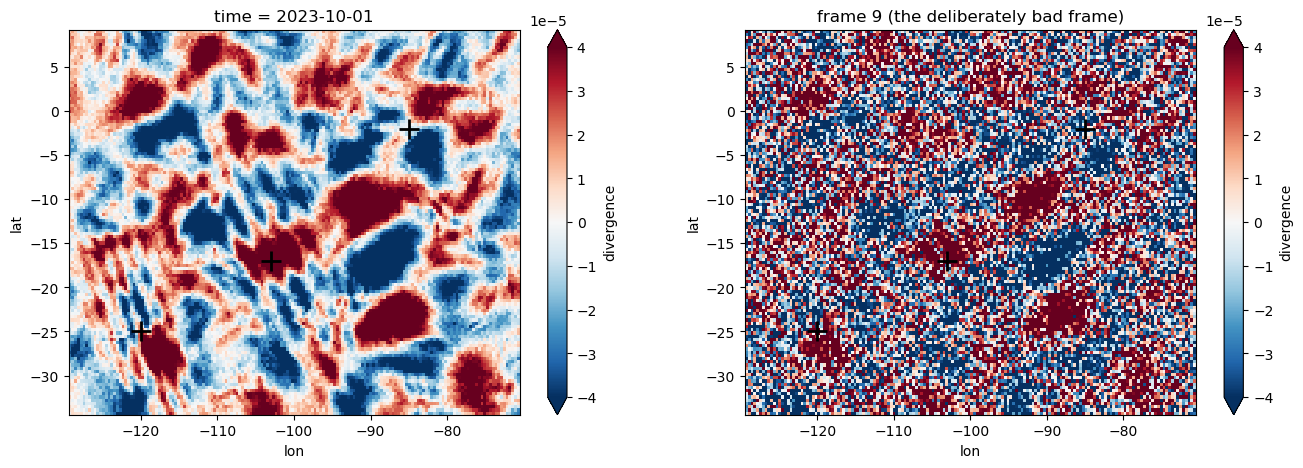

In [19]:
if INPUT_FILE.exists():
    _ref = xr.open_dataset(INPUT_FILE).sortby("lat")
    lat_src, lon_src = _ref.lat.values.astype(float), _ref.lon.values.astype(float)
    dt_src = float(np.median(np.diff(_ref.time.values[:50]) / np.timedelta64(1, "s")))
else:
    lat_src = np.linspace(-34.26, 9.042, 120); lon_src = np.linspace(-129.3, -70.7, 162); dt_src = 1800.0

n_frames = T_START + N_BATCHES * BATCH + 1
syn = synth_dataset(lat_src, lon_src, n_frames, dt_src)
grid = MercGrid(lat_src, lon_src)
bank = WaveletBank(grid, CFG)
print(grid, f"\nΔt = {dt_src:.0f} s, {n_frames} synthetic frames")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
v = 4e-5
syn[DIV_VAR].isel(time=0).plot(ax=ax[0], cmap="RdBu_r", vmin=-v, vmax=v)
syn[DIV_VAR].isel(time=SYN_NOISE["bad_frame"]).plot(ax=ax[1], cmap="RdBu_r", vmin=-v, vmax=v)
for a_ in ax:
    a_.plot(SYN_WAVES.lon, SYN_WAVES.lat, "k+", ms=14, mew=2)
ax[1].set_title(f"frame {SYN_NOISE['bad_frame']} (the deliberately bad frame)")
plt.show()

In [20]:
res_syn = analyze(syn, grid, bank)

batch 0: 2023-10-01T00:00 + 6 pairs, Δt = 1800 s
batch 1: 2023-10-01T03:00 + 6 pairs, Δt = 1800 s
batch 2: 2023-10-01T06:00 + 6 pairs, Δt = 1800 s
batch 3: 2023-10-01T09:00 + 6 pairs, Δt = 1800 s


### 9a. Did the wind come out right?

The table compares, per box, the true wind at the box centre with the wavelet fit and the PIV box median, averaged
over batches.

,wavelet_fit_rms_err,piv_median_rms_err,boxes_with_fit,boxes_total
m/s,0.76,0.04,108,108


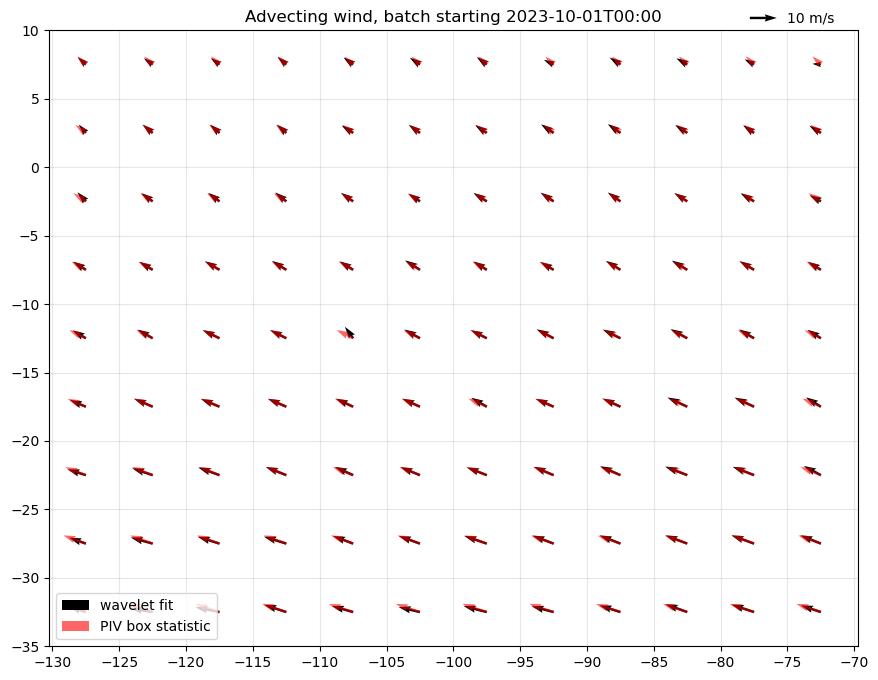

In [21]:
Ut, Vt = syn_wind(res_syn.box_lat.values[:, None] + 0 * res_syn.box_lon.values[None, :])
cmp = pd.DataFrame(dict(
    wavelet_fit_rms_err=[float(np.sqrt(np.nanmean((res_syn.U_fit.mean("batch") - Ut) ** 2 +
                                                  (res_syn.V_fit.mean("batch") - Vt) ** 2)))],
    piv_median_rms_err=[float(np.sqrt(np.nanmean((res_syn.U_piv.mean("batch") - Ut) ** 2 +
                                                 (res_syn.V_piv.mean("batch") - Vt) ** 2)))],
    boxes_with_fit=[int(np.isfinite(res_syn.U_fit.mean("batch")).sum())],
    boxes_total=[int(res_syn.box_lat.size * res_syn.box_lon.size)]), index=["m/s"])
display(cmp.round(2))
plot_wind_map(res_syn)

### 9b. One box in detail

The diagnostic box is set to contain the first synthetic wave (300 km, travelling toward 60° at 12 m/s relative
to the wind). Expect the 200–400 km points near θ = 60° to sit well above the sinusoid (by up to 12 m/s; see 9c
for why it is usually less); everything else should follow it.

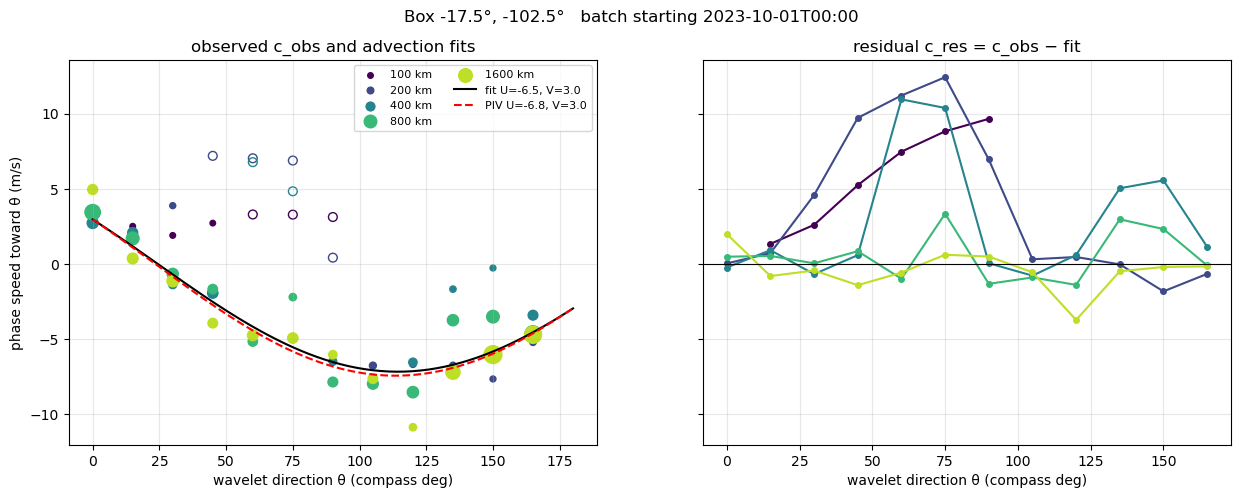

In [22]:
plot_box_diagnostic(res_syn, DIAG_BOX, batch=0)

### 9c. Recovery of the waves

For each synthetic wave, in its box and at the bank angle nearest its direction, the batch-mean residual at every
scale, together with the coherence and amplitude there. The wave's own scale should carry a residual close to its
true speed, with the right sign: positive if it travels toward θ, negative if toward θ + 180°.

In [23]:
def wave_recovery(res, waves):
    rows = []
    for p in waves.itertuples():
        r = res.sel(**nearest_box(res, (p.lat, p.lon)))
        a = int(np.argmin(np.abs((r.angle.values - p.dir_deg % 180 + 90) % 180 - 90)))
        th = float(r.angle[a])
        expected = p.c * np.cos(np.radians(p.dir_deg - th))       # + if travelling toward th
        for s in r.scale.values:
            rs = r.sel(scale=s).isel(angle=a)
            rows.append(dict(wave=f"{p.lam_km} km toward {p.dir_deg}°, c = {p.c}", theta=th, scale_km=s,
                             expected_c_res=round(expected, 1), c_res=round(float(rs.c_res.mean("batch")), 1),
                             coherence=round(float(rs.coherence.mean("batch")), 2),
                             amplitude_1e5=round(float(rs.amplitude.mean("batch")) * 1e5, 2)))
    return pd.DataFrame(rows).set_index(["wave", "scale_km"])


display(wave_recovery(res_syn, SYN_WAVES))

theta  expected_c_res  c_res  \
wave                         scale_km                                 
300 km toward 60°, c = 12.0  100.0      60.0            12.0    8.4   
                             200.0      60.0            12.0   11.5   
                             400.0      60.0            12.0   11.3   
                             800.0      60.0            12.0   -0.5   
                             1600.0     60.0            12.0   -1.0   
200 km toward 250°, c = 8.0  100.0      75.0            -8.0   -1.8   
                             200.0      75.0            -8.0   -6.7   
                             400.0      75.0            -8.0   -2.7   
                             800.0      75.0            -8.0   -1.1   
                             1600.0     75.0            -8.0   -3.1   
600 km toward 140°, c = 15.0 100.0     135.0            14.9    2.3   
                             200.0     135.0            14.9    6.2   
                             400.0     135.0            14.9   16.4   
                             800.0     135.0            14.9   15.2   
                             1600.0    135.0            14.9   -0.8   

                                       coherence  amplitude_1e5  
wave                         scale_km                            
300 km toward 60°, c = 12.0  100.0          0.56           0.21  
                             200.0          0.99           1.33  
                             400.0          1.00           1.76  
                             800.0          0.99           0.42  
                             1600.0         1.00           0.60  
200 km toward 250°, c = 8.0  100.0          0.57           0.25  
                             200.0          0.97           0.71  
                             400.0          0.98           0.49  
                             800.0          1.00           0.91  
                             1600.0         1.00           0.47  
600 km toward 140°, c = 15.0 100.0          0.46           0.20  
                             200.0          0.80           0.27  
                             400.0          1.00           1.33  
                             800.0          1.00           1.37  
                             1600.0         1.00           0.98

**Reading the table.** Look at the scales where the amplitude is largest: those carry the wave. There the
residual should approach the expected value. It is usually somewhat smaller, for an instructive reason: a wavelet
coefficient mixes the wave with the advected background at the same scale and angle, and the summed phase change is
their **energy-weighted average**. So c_res ≈ c × (wave's share of the energy there). It is closest to c where the
wave dominates (e.g. a wave falling right on a bank scale), and diluted where the wave falls between bank scales or
the background is strong. Scales far from the wave's wavelength show only background noise, typically ±1–2 m/s.

The sign tells direction: the 200 km wave travels toward 250°, so at θ = 75° its residual is negative.

### 9d. Where are the wave candidates, and do they persist?

The residual roses should show spokes at the three wave locations, pointing in the waves' directions of travel,
and little elsewhere. The persistence panels show the bad frame: it falls in one batch only, so its effect
appears in one column and is rejected by the persistence criterion.

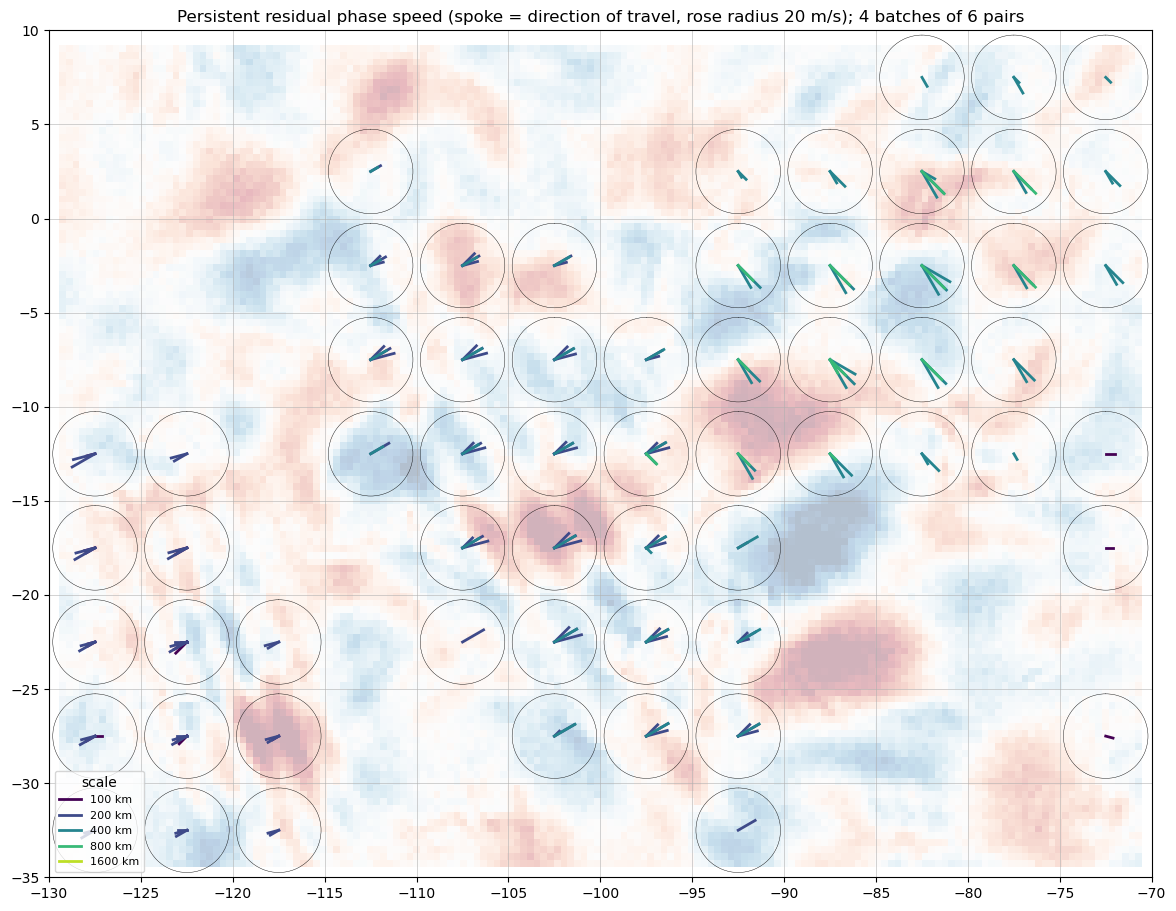

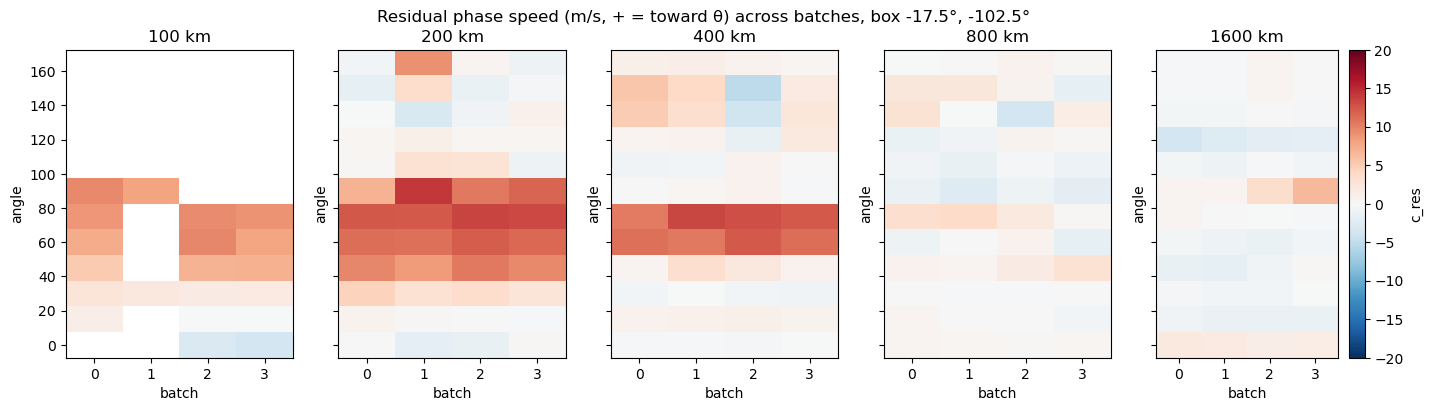

In [24]:
plot_residual_roses(res_syn, background=(lon_src, lat_src, syn[DIV_VAR].isel(time=0).values))
plot_persistence(res_syn, DIAG_BOX)

## 10. Real data

The same `analyze` call on the PIV file. First, the data's resolution and the aliasing limits it implies: for each
scale, the largest phase speed whose phase change stays within ±180° per time step (λ / 2Δt, using the physical
wavelength at the domain's central latitude). Speeds near or above that limit rely on the prior unwrapping.

In [25]:
if INPUT_FILE.exists():
    ds = xr.open_dataset(INPUT_FILE).sortby("lat")
    grid = MercGrid(ds.lat.values, ds.lon.values)
    bank = WaveletBank(grid, CFG)
    dt = float(np.median(np.diff(ds.time.values[:200]) / np.timedelta64(1, "s")))
    coslat = np.cos(np.radians(float(ds.lat.mean())))
    print(grid)
    display(pd.DataFrame(dict(scale_km=bank.lams, physical_lambda_km=(bank.lams * coslat).round(0),
                              max_unambiguous_speed_mps=(bank.lams * coslat * 1000 / (2 * dt)).round(1))))
    print(f"Δt = {dt:.0f} s, {ds.sizes['time']} frames; analysing frames {T_START}..{T_START + N_BATCHES * BATCH}")
else:
    ds = None
    print(f"Input file not found: {INPUT_FILE}  -- set INPUT_FILE in section 1.")

WaveletBank: 5 scales x 12 angles, padded FFT 210 x 242 (pad 40 px = 1618 km), filters 37 MB
MercGrid: 126 x 162, dx = 40.45 km, lat -34.26..8.93, lon -129.27..-70.70


,scale_km,physical_lambda_km,max_unambiguous_speed_mps
0,100.0,98.0,27.1
1,200.0,195.0,54.2
2,400.0,390.0,108.4
3,800.0,781.0,216.9
4,1600.0,1561.0,433.7


Δt = 1800 s, 4277 frames; analysing frames 0..24


batch 0: 2023-09-01T00:00 + 6 pairs, Δt = 1800 s
batch 1: 2023-09-01T03:00 + 6 pairs, Δt = 1800 s
batch 2: 2023-09-01T06:00 + 6 pairs, Δt = 1800 s
batch 3: 2023-09-01T09:00 + 6 pairs, Δt = 1800 s


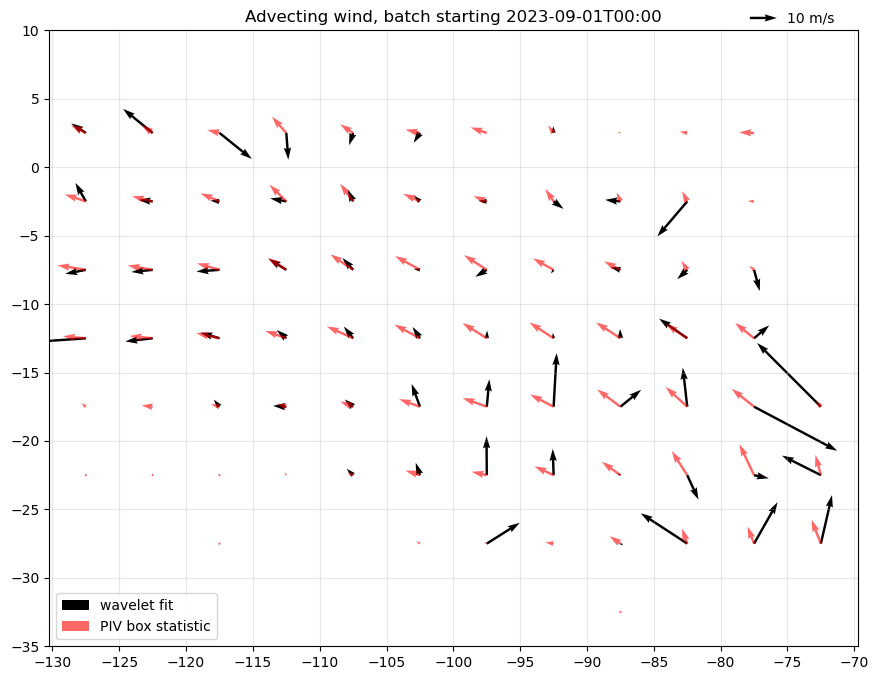

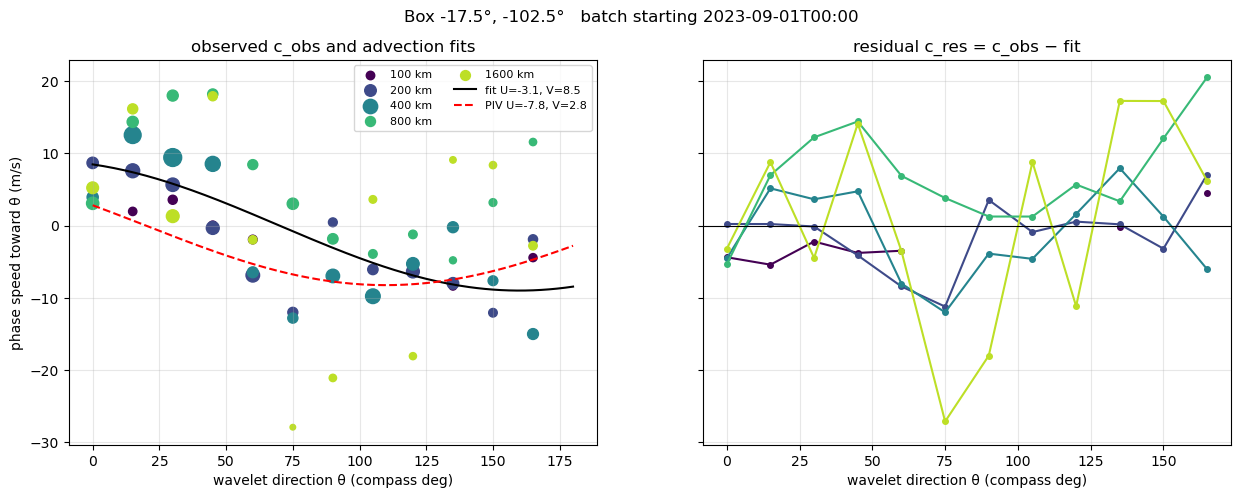

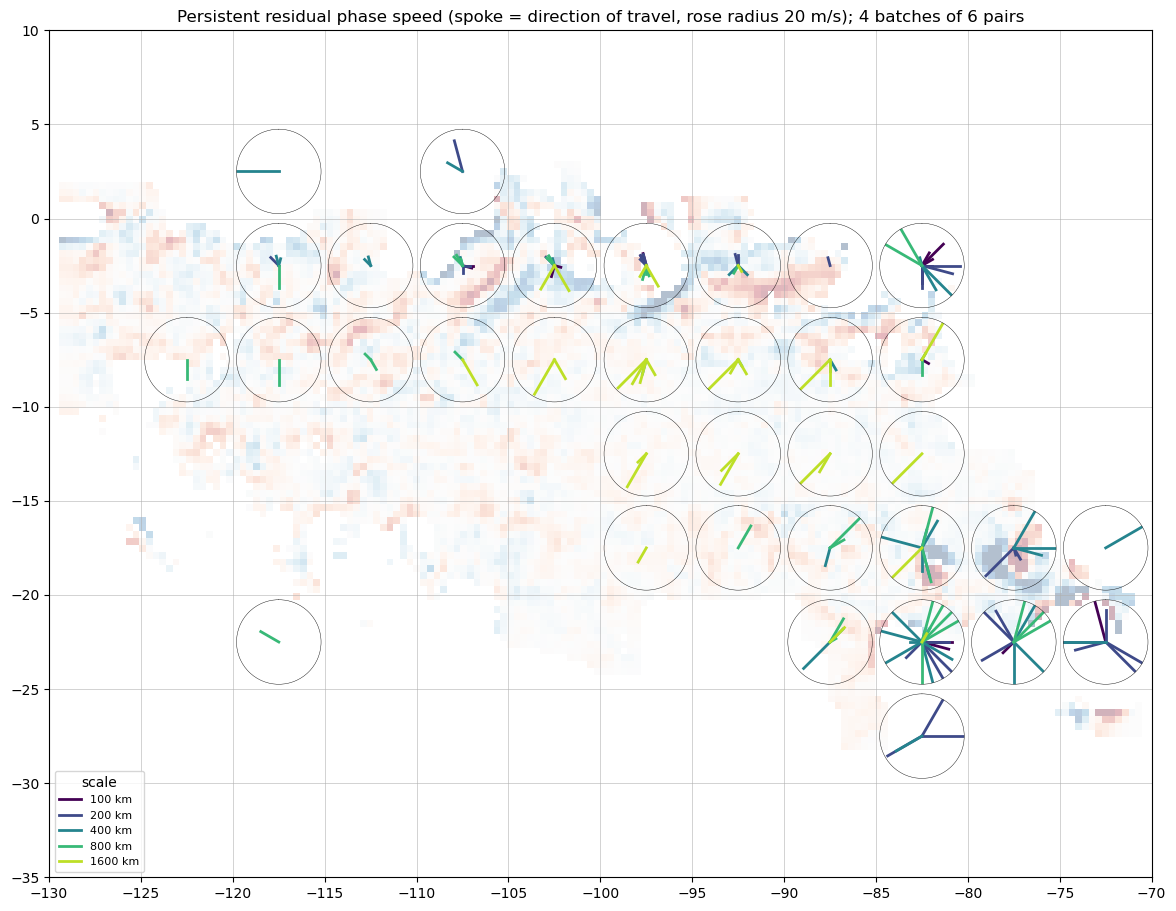

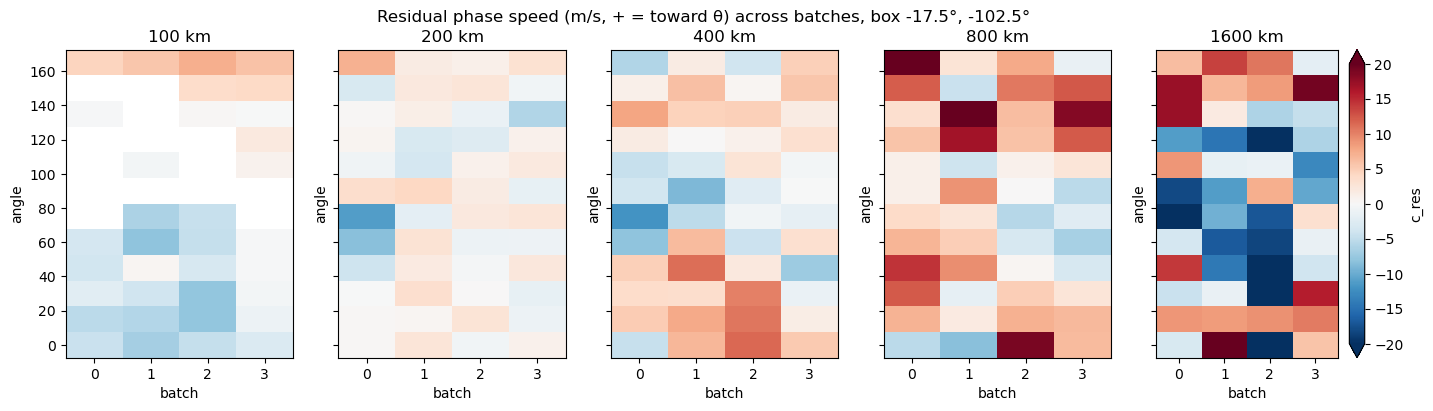

In [26]:
if ds is not None:
    res = analyze(ds, grid, bank)
    plot_wind_map(res)
    plot_box_diagnostic(res, DIAG_BOX)
    plot_residual_roses(res, background=(ds.lon.values, ds.lat.values, ds[DIV_VAR].isel(time=T_START).values))
    plot_persistence(res, DIAG_BOX)

## 11. Things to try

- **Batch length** (`BATCH`): longer batches average more pairs (less noise) but blur waves that change or move
  between boxes. Compare 3, 6 and 12.
- **Coherence threshold** (`COH_MIN`): lower admits more estimates (and more noise) into the fit and the roses.
- **Box size** (`BOX_DEG`): smaller boxes resolve wind variations and keep wave packets from being diluted, but hold
  fewer pixels at large scales.
- **Nominal vs local wavenumber** (`K_MODE`): compare the fitted winds; differences show how much the spectrum's
  slope biases the nominal wavenumber.
- **Prior unwrapping** off (`USE_PRIOR_UNWRAP = False`): differences appear only at small scales and fast winds,
  exactly where the aliasing table says they should.
- **Scale dependence**: in the box diagnostic, a residual that grows or shrinks systematically with scale at the
  same angle is a hint of dispersion; a single-scale residual is a narrowband packet.